# Problem 6 · Lid-driven cavity flow

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *A square cavity is filled with a viscous fluid. Its lid slides to the right at a constant speed while the other three walls stay at rest. Find the steady flow inside the cavity at Reynolds number 100 with the Finite Difference Method, and compare it with the benchmark solution of Ghia, Ghia & Shin (1982).*

This is the first problem of the course in which we solve the **Navier–Stokes equations** themselves: the fluid's own velocity is the unknown. It is also the most famous test case of CFD: almost every new flow solver is checked on it.

In this notebook we solve the problem **step by step, following the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | describe the cavity and the moving lid, and compute the Reynolds number |
| 2 · Grid | cover the square with a 33 × 33 grid of nodes |
| 3 · Physics | rewrite the Navier–Stokes equations with the stream function and the vorticity |
| 4 · Numerical scheme | five-point Poisson equation (Problem 3), central convection (Problem 5), wall vorticity |
| 5 · Solution setup | couple the two equations in one Gauss–Seidel iteration |
| 6 · Compute | iterate until nothing changes any more |
| 7 · Post-processing | streamlines, vorticity, velocity profiles, vortex centre, grid study, benchmark |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only import used in the calculations is `math` (part of Python itself), for `log` in the order of accuracy, and `time`, to measure how long the solver runs. The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python: log
import time     # built into Python: measure the run time
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

Picture a square box full of fluid, open at the top, with a long plate (the **lid**) sliding across the opening. Friction drags the fluid just under the lid to the right. That fluid hits the right wall, turns down, flows back to the left along the bottom and rises up the left wall: a big **vortex** fills the cavity. The same flow appears in a groove on a moving surface, in a coating machine, or in the gap between a ship's hull and a dock.

| Quantity | Symbol | Value |
|---|:-:|---|
| side of the square cavity | $L$ | 1 m |
| speed of the lid | $U$ | 1 m/s |
| kinematic viscosity of the fluid | $\nu$ | 0.01 m²/s |

**Assumptions:** two-dimensional (the cavity is very long in the third direction), incompressible, Newtonian fluid with constant viscosity, steady flow, no gravity effects.

Only one number matters: the **Reynolds number**, the ratio of inertia (the fluid's tendency to keep moving) to viscous friction:

$$Re = \frac{U L}{\nu}.$$

Any cavity with the same $Re$ has the same flow pattern, for example water ($\nu = 10^{-6}$ m²/s) in a 1 cm cavity with a lid moving at 1 cm/s.

In [2]:
L = 1.0           # side of the cavity              [m]
U = 1.0           # speed of the lid                [m/s]
nu = 0.01         # kinematic viscosity             [m^2/s]

Re = U * L / nu
print(f"Reynolds number Re = U L / nu = {Re:g}")

Reynolds number Re = U L / nu = 100


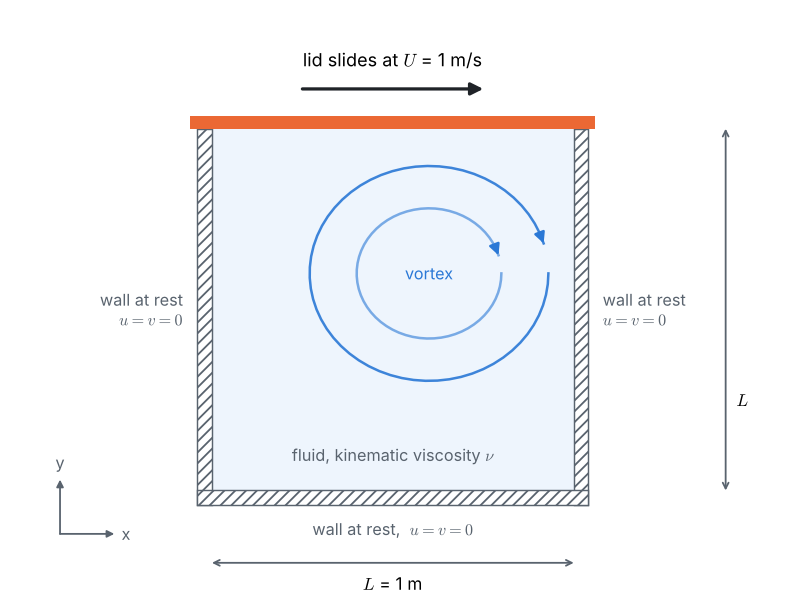

In [3]:
plots.schematic(L, U)

---
## Pillar 2 · The grid

As in Problems 3 and 4, we cover the square with a uniform grid: $N$ intervals in each direction, spacing $h = L/N$, nodes $(i, j)$ at $x_i = i\,h$ and $y_j = j\,h$, with $i$ counting to the right and $j$ counting upwards. The nodes on the edges are wall nodes; the $(N-1)^2$ nodes inside are the unknowns.

We use $N = 32$: 33 × 33 = 1089 nodes, of which 961 are unknown. That is far too many for a hand calculation, but takes the computer less than a second.

In [4]:
N = 32                    # number of intervals in each direction
h = L / N                 # grid spacing [m]

x = [i * h for i in range(N + 1)]    # node positions (the same list serves for y)

print(f"N = {N} intervals, h = {h:.5f} m, {(N + 1) ** 2} nodes, {(N - 1) ** 2} unknown nodes per variable")
print(f"cell Reynolds number U h / nu = {U * h / nu:.3f}")

N = 32 intervals, h = 0.03125 m, 1089 nodes, 961 unknown nodes per variable
cell Reynolds number U h / nu = 3.125


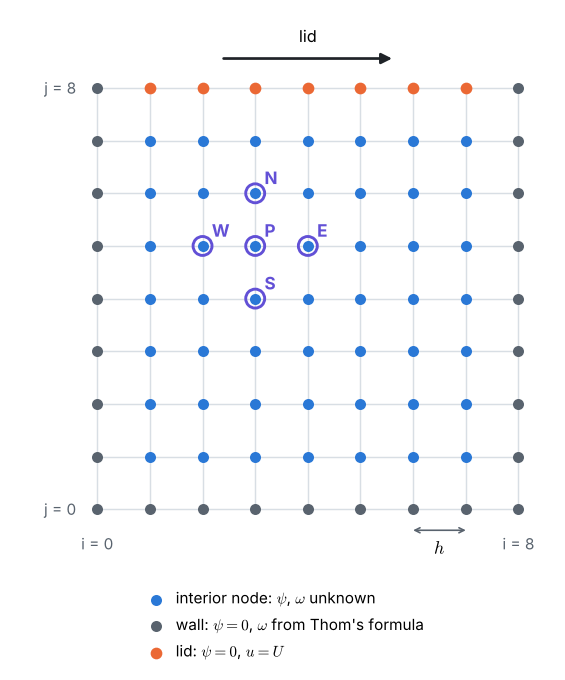

In [5]:
plots.grid(8)

The figure shows the grid with $N = 8$ so that the nodes can be seen; the notebook uses $N = 32$. The last line printed above is the **cell Reynolds number** $U h/\nu$, the cell Péclet number of Problem 5 for momentum. It is above 2 next to the lid: we will come back to that in Pillar 7.

---
## Pillar 3 · Physics: the Navier–Stokes equations, rewritten

For a steady, incompressible, two-dimensional flow with velocity $(u, v)$ and pressure $p$, the conservation of mass (continuity) and of momentum (Navier–Stokes) read

$$\frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} = 0,$$

$$u\frac{\partial u}{\partial x} + v\frac{\partial u}{\partial y} = -\frac{1}{\rho}\frac{\partial p}{\partial x} + \nu\,\nabla^2 u,
\qquad
u\frac{\partial v}{\partial x} + v\frac{\partial v}{\partial y} = -\frac{1}{\rho}\frac{\partial p}{\partial y} + \nu\,\nabla^2 v.$$

Three unknowns ($u$, $v$, $p$), and an awkward pressure that has no equation of its own. A classic trick removes the pressure and satisfies continuity automatically.

**1 · The stream function** $\psi$. Define the velocity from it:

$$u = \frac{\partial \psi}{\partial y}, \qquad v = -\frac{\partial \psi}{\partial x}.$$

Then $\partial u/\partial x + \partial v/\partial y = \psi_{yx} - \psi_{xy} = 0$: **continuity holds for any $\psi$**. Lines of constant $\psi$ are **streamlines**, and the difference of $\psi$ between two streamlines is the flow rate between them.

**2 · The vorticity** $\omega$, the local spin of the fluid:

$$\omega = \frac{\partial v}{\partial x} - \frac{\partial u}{\partial y} \quad\Longrightarrow\quad \nabla^2\psi = -\,\omega.$$

**3 · The vorticity transport equation.** Differentiate the $u$-momentum equation with respect to $y$, the $v$-momentum equation with respect to $x$, and subtract: the pressure cancels, and what is left is

$$\underbrace{u\,\frac{\partial \omega}{\partial x} + v\,\frac{\partial \omega}{\partial y}}_{\text{convection (Problem 5)}} = \underbrace{\nu\,\nabla^2 \omega}_{\text{diffusion}}.$$

So two equations replace three, and both are old friends:

| Equation | Type | Met in |
|---|---|---|
| $\nabla^2\psi = -\omega$ | Poisson (elliptic) | Problem 3 (the Laplace equation with a source) |
| $u\,\omega_x + v\,\omega_y = \nu\,\nabla^2\omega$ | convection–diffusion | Problem 5, now in 2D |

The two are **coupled**: the velocities in the second equation come from $\psi$, and the source of the first equation is $\omega$.

**Boundary conditions.**

* **Stream function.** No fluid crosses a wall, so every wall is a streamline: $\psi = 0$ on all four walls.
* **Vorticity.** The fluid sticks to the walls (**no slip**): $u = U$ on the lid, $u = v = 0$ on the other walls. The vorticity on a wall is not given directly; we will compute it from $\psi$ in Pillar 4 (Thom's formula).

There is **no exact solution**. Instead we compare with the classic **benchmark** of U. Ghia, K. N. Ghia and C. T. Shin (*Journal of Computational Physics* 48, 1982, 387–411), who solved this flow on a 129 × 129 grid. Their tables of the velocity along the two centre lines are used in every CFD course. For $Re = 100$:

In [6]:
# Ghia, Ghia & Shin (1982), Re = 100: u along the vertical centre line x = 0.5 ...
ghia_y = [1.0000, 0.9766, 0.9688, 0.9609, 0.9531, 0.8516, 0.7344, 0.6172, 0.5000,
          0.4531, 0.2813, 0.1719, 0.1016, 0.0703, 0.0625, 0.0547, 0.0000]
ghia_u = [1.00000, 0.84123, 0.78871, 0.73722, 0.68717, 0.23151, 0.00332, -0.13641, -0.20581,
          -0.21090, -0.15662, -0.10150, -0.06434, -0.04775, -0.04192, -0.03717, 0.00000]
# ... and v along the horizontal centre line y = 0.5
ghia_x = [1.0000, 0.9688, 0.9609, 0.9531, 0.9453, 0.9063, 0.8594, 0.8047, 0.5000,
          0.2344, 0.2266, 0.1563, 0.0938, 0.0781, 0.0703, 0.0625, 0.0000]
ghia_v = [0.00000, -0.05906, -0.07391, -0.08864, -0.10313, -0.16914, -0.22445, -0.24533, 0.05454,
          0.17527, 0.17507, 0.16077, 0.12317, 0.10890, 0.10091, 0.09233, 0.00000]
# ... and the primary vortex: minimum of psi and its position
ghia_psi_min, ghia_centre = -0.103423, (0.6172, 0.7344)

print(f"Ghia et al.: primary vortex psi = {ghia_psi_min} m^2/s at (x, y) = {ghia_centre} m")

Ghia et al.: primary vortex psi = -0.103423 m^2/s at (x, y) = (0.6172, 0.7344) m


---
## Pillar 4 · Numerical scheme

We store $\psi$ and $\omega$ as lists of rows, `psi[j][i]` and `w[j][i]`: row $j$ (height $y_j$), column $i$ (position $x_i$). For an interior node $P = (i, j)$ we call its neighbours $E = (i+1, j)$, $W = (i-1, j)$, $N = (i, j+1)$ and $S = (i, j-1)$.

**1 · Stream function: the five-point formula (Problem 3).** Central differences for $\nabla^2\psi = -\omega$ give

$$\frac{\psi_E + \psi_W + \psi_N + \psi_S - 4\psi_P}{h^2} = -\,\omega_P
\quad\Longrightarrow\quad
\psi_P = \frac{\psi_E + \psi_W + \psi_N + \psi_S + h^2\,\omega_P}{4}.$$

**2 · Velocities**, by central differences of $\psi$:

$$u_P = \frac{\psi_N - \psi_S}{2h}, \qquad v_P = -\,\frac{\psi_E - \psi_W}{2h}.$$

**3 · Vorticity: central differences for convection and diffusion (Problem 5).** Inserting
$\omega_x \approx (\omega_E - \omega_W)/(2h)$, $\omega_y \approx (\omega_N - \omega_S)/(2h)$ and the five-point Laplacian into $u\,\omega_x + v\,\omega_y = \nu\,\nabla^2\omega$, and multiplying by $h^2/\nu$:

$$\omega_P = \frac{1}{4}\Big[\big(1 - \tfrac{R_x}{2}\big)\,\omega_E + \big(1 + \tfrac{R_x}{2}\big)\,\omega_W + \big(1 - \tfrac{R_y}{2}\big)\,\omega_N + \big(1 + \tfrac{R_y}{2}\big)\,\omega_S\Big],
\qquad R_x = \frac{u_P\,h}{\nu},\quad R_y = \frac{v_P\,h}{\nu}.$$

These are exactly the CDS coefficients of Problem 5, $a_W = D + F/2$ and $a_E = D - F/2$, now in two directions, with the **local cell Reynolds numbers** $R_x$ and $R_y$ in the role of $Pe_\Delta$. The downstream coefficients become negative where $|R_x| > 2$ or $|R_y| > 2$.

**4 · Wall vorticity: Thom's formula.** Take the moving lid ($j = N$) and expand $\psi$ from the wall one step down, with a Taylor series:

$$\psi_{N-1} = \psi_{wall} - h\,\frac{\partial\psi}{\partial y}\bigg|_{wall} + \frac{h^2}{2}\,\frac{\partial^2\psi}{\partial y^2}\bigg|_{wall} - \dots$$

On the lid $\psi_{wall} = 0$ and $\partial\psi/\partial y = u = U$. Along the wall $v = 0$ everywhere, so $\partial v/\partial x = 0$ and $\omega_{wall} = -\partial u/\partial y = -\partial^2\psi/\partial y^2$. Solving for $\omega_{wall}$:

$$\omega_{lid} = -\,\frac{2\,\psi_{N-1}}{h^2} - \frac{2\,U}{h}, \qquad \omega_{wall} = -\,\frac{2\,\psi_{adjacent}}{h^2} \;\;\text{(the three walls at rest)}.$$

The corner nodes never appear in the five-point formulas, so their values do not matter.

In [7]:
def wall_vorticity(psi, w, N, h):
    """Thom's formula: vorticity on the four walls from the psi of the first interior nodes."""
    for k in range(N + 1):
        w[0][k] = -2 * psi[1][k] / h**2                    # bottom wall, at rest
        w[k][0] = -2 * psi[k][1] / h**2                    # left wall, at rest
        w[k][N] = -2 * psi[k][N - 1] / h**2                # right wall, at rest
        w[N][k] = -2 * psi[N - 1][k] / h**2 - 2 * U / h    # moving lid (top)

---
## Pillar 5 · Solution setup: one iteration for two coupled equations

We start from a fluid at rest ($\psi = 0$ and $\omega = 0$ everywhere) and repeat three steps until nothing changes any more:

1. **wall vorticity** from the current $\psi$ (Thom's formula);
2. one **Gauss–Seidel sweep** of the vorticity equation over all interior nodes, with the velocities computed from the current $\psi$;
3. one **Gauss–Seidel sweep** of the Poisson equation for $\psi$, with the new $\omega$.

As in Problems 1, 3 and 4, Gauss–Seidel always uses the newest values. In the very first iteration all velocities are zero, so the vorticity sweep is pure diffusion: the lid vorticity $-2U/h$ leaks into the first row of nodes under the lid, and the $\psi$ sweep turns it into a first, weak flow. The flow then spins up, iteration by iteration.

We stop when the largest change of $\omega$ and the largest change of $\psi$ in one iteration are both below a tolerance of $10^{-6}$ (in their own units, 1/s and m²/s).

In the code, the half cell Reynolds numbers are computed straight from $\psi$: with $u_P = (\psi_N - \psi_S)/(2h)$, $\;R_x/2 = u_P h/(2\nu) = (\psi_N - \psi_S)/(4\nu)$, and likewise $R_y/2 = (\psi_W - \psi_E)/(4\nu)$.

> **Why not over-relaxation?** Over-relaxing the $\psi$ sweep (SOR, Problem 3) roughly halves the number of iterations on fine grids, but in our tests it made the coarse grids ($N = 4$ and $8$) diverge. Plain Gauss–Seidel converged on every grid we tried, so we keep it simple.

In [8]:
def solve_cavity(N, Re, tol=1e-6, max_iter=100_000):
    """Steady lid-driven cavity: Gauss-Seidel on the vorticity and stream-function equations."""
    h = L / N
    nu = U * L / Re
    k = 1 / (4 * nu)                      # turns a difference of psi into half a cell Reynolds number
    psi = [[0.0] * (N + 1) for _ in range(N + 1)]    # psi[j][i]: fluid at rest
    w = [[0.0] * (N + 1) for _ in range(N + 1)]      # w[j][i]
    changes = []                          # largest change of (w, psi) in every iteration

    for iteration in range(max_iter):
        # step 1: vorticity on the walls (Thom's formula)
        wall_vorticity(psi, w, N, h)

        # step 2: one Gauss-Seidel sweep of the vorticity transport equation
        largest_w = 0.0
        for j in range(1, N):
            for i in range(1, N):
                half_Rx = (psi[j + 1][i] - psi[j - 1][i]) * k     # u h / (2 nu)
                half_Ry = (psi[j][i - 1] - psi[j][i + 1]) * k     # v h / (2 nu)
                new = ((1 - half_Rx) * w[j][i + 1] + (1 + half_Rx) * w[j][i - 1]
                       + (1 - half_Ry) * w[j + 1][i] + (1 + half_Ry) * w[j - 1][i]) / 4
                largest_w = max(largest_w, abs(new - w[j][i]))
                w[j][i] = new

        # step 3: one Gauss-Seidel sweep of the Poisson equation for psi
        largest_psi = 0.0
        for j in range(1, N):
            for i in range(1, N):
                new = (psi[j][i + 1] + psi[j][i - 1] + psi[j + 1][i] + psi[j - 1][i]
                       + h * h * w[j][i]) / 4
                largest_psi = max(largest_psi, abs(new - psi[j][i]))
                psi[j][i] = new

        changes.append((largest_w, largest_psi))
        if largest_w < tol and largest_psi < tol:        # converged
            break

    return psi, w, changes

Once $\psi$ is known, the velocities follow from Pillar 4 (on the walls they are the no-slip values):

In [9]:
def velocities(psi, N):
    """u and v at every node from central differences of psi (no-slip values on the walls)."""
    h = L / N
    u = [[0.0] * (N + 1) for _ in range(N + 1)]
    v = [[0.0] * (N + 1) for _ in range(N + 1)]
    for i in range(N + 1):
        u[N][i] = U                                   # the lid
    for j in range(1, N):
        for i in range(1, N):
            u[j][i] = (psi[j + 1][i] - psi[j - 1][i]) / (2 * h)
            v[j][i] = -(psi[j][i + 1] - psi[j][i - 1]) / (2 * h)
    return u, v

---
## Pillar 6 · Compute

In [10]:
start = time.time()
psi, w, changes = solve_cavity(N, Re)
seconds = time.time() - start

print(f"converged after {len(changes)} iterations ({seconds:.1f} s)")
print(f"last changes: vorticity {changes[-1][0]:.1e} 1/s, stream function {changes[-1][1]:.1e} m^2/s")

converged after 905 iterations (0.6 s)
last changes: vorticity 1.0e-06 1/s, stream function 1.3e-08 m^2/s


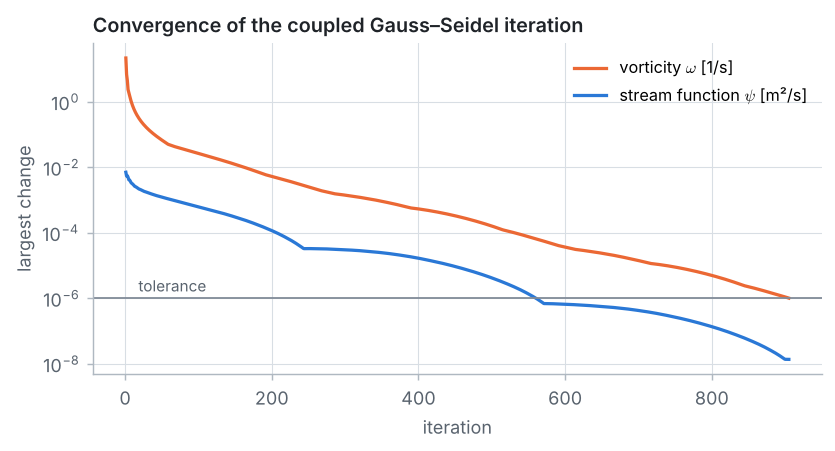

In [11]:
plots.iterations(changes, 1e-6)

The changes are largest in the first iterations, while the flow spins up from rest and the vortex forms, then fall steadily until both drop below the tolerance.

A small change per iteration is not the same as a small error, as we saw in Problem 1. Is $10^{-6}$ tight enough? Run again with a tolerance 100 times smaller and compare:

In [12]:
psi_tight, w_tight, changes_tight = solve_cavity(N, Re, tol=1e-8)
largest = max(abs(psi_tight[j][i] - psi[j][i]) for j in range(N + 1) for i in range(N + 1))
print(f"tol = 1e-8: {len(changes_tight)} iterations; psi changes by at most {largest:.1e} m^2/s")

tol = 1e-8: 1299 iterations; psi changes by at most 1.7e-06 m^2/s


The stream function changes by less than $2 \times 10^{-6}$ m²/s, more than a thousand times less than the change caused by refining the grid (see the grid study below), so the tolerance is not what limits the accuracy.

### Checking the whiteboard numbers

The whiteboard guide does the first iteration by hand on the coarsest possible grid, $N = 4$ (9 interior nodes). Because the iteration always starts from rest, `solve_cavity(4, Re, max_iter=1)` returns exactly the fields after one iteration, and without `max_iter` it returns the converged fields. Rows are printed from the lid ($j = 4$) down to the bottom ($j = 0$):

In [13]:
def show(field, digits):
    """Print a field row by row, from the lid down (+ 0.0 turns -0.0 into 0.0)."""
    for j in range(len(field) - 1, -1, -1):
        print(f"   j = {j}: " + "  ".join(f"{value + 0.0:{digits + 4}.{digits}f}" for value in field[j]))


for label, iterations in (("after iteration 1", 1), ("after iteration 2", 2), ("converged", 100_000)):
    psi_h, w_h, changes_h = solve_cavity(4, Re, max_iter=iterations)
    print(f"N = 4, {label} ({len(changes_h)} iterations)")
    print("  vorticity w [1/s]:")
    show(w_h, 4)
    print("  stream function psi [m^2/s]:")
    show(psi_h, 6)

N = 4, after iteration 1 (1 iterations)
  vorticity w [1/s]:
   j = 4:   0.0000   -8.0000   -8.0000   -8.0000   -8.0000
   j = 3:   0.0000   -2.0000   -2.5000   -2.6250    0.0000
   j = 2:   0.0000    0.0000    0.0000    0.0000    0.0000
   j = 1:   0.0000    0.0000    0.0000    0.0000    0.0000
   j = 0:   0.0000    0.0000    0.0000    0.0000    0.0000
  stream function psi [m^2/s]:
   j = 4:   0.000000    0.000000    0.000000    0.000000    0.000000
   j = 3:   0.000000   -0.031250   -0.046875   -0.052734    0.000000
   j = 2:   0.000000    0.000000    0.000000    0.000000    0.000000
   j = 1:   0.000000    0.000000    0.000000    0.000000    0.000000
   j = 0:   0.000000    0.000000    0.000000    0.000000    0.000000
N = 4, after iteration 2 (2 iterations)
  vorticity w [1/s]:
   j = 4:   0.0000   -7.0000   -6.5000   -6.3125   -8.0000
   j = 3:   1.0000   -0.3457   -1.7268   -3.4112    1.6875
   j = 2:   0.0000   -0.5000   -0.6035   -0.6082    0.0000
   j = 1:   0.0000    0.0000  

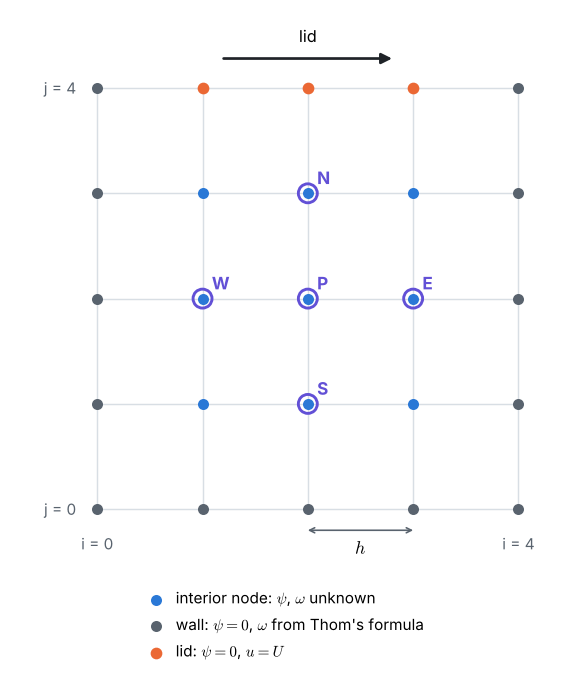

In [14]:
plots.grid(4)

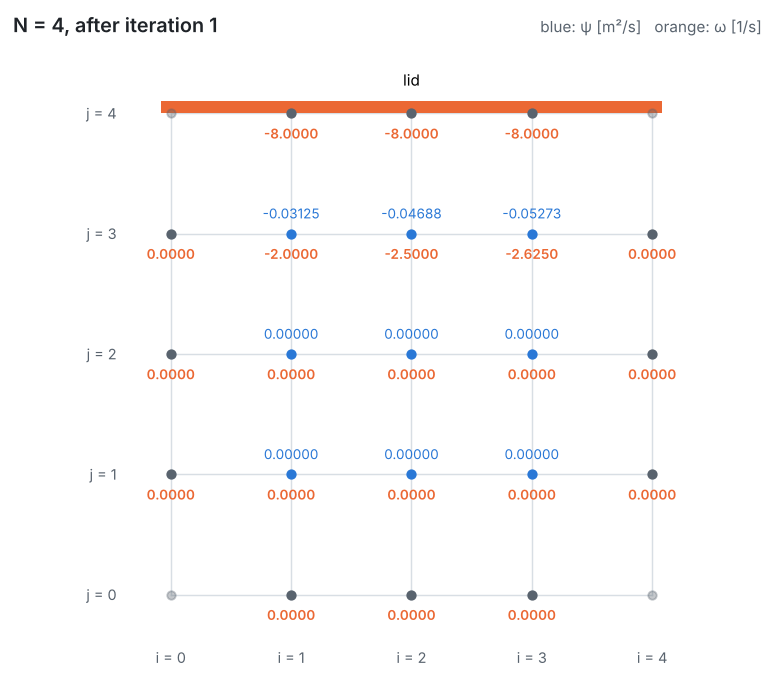

In [15]:
psi_h, w_h, _ = solve_cavity(4, Re, max_iter=1)
plots.hand_grid(psi_h, w_h, "N = 4, after iteration 1")

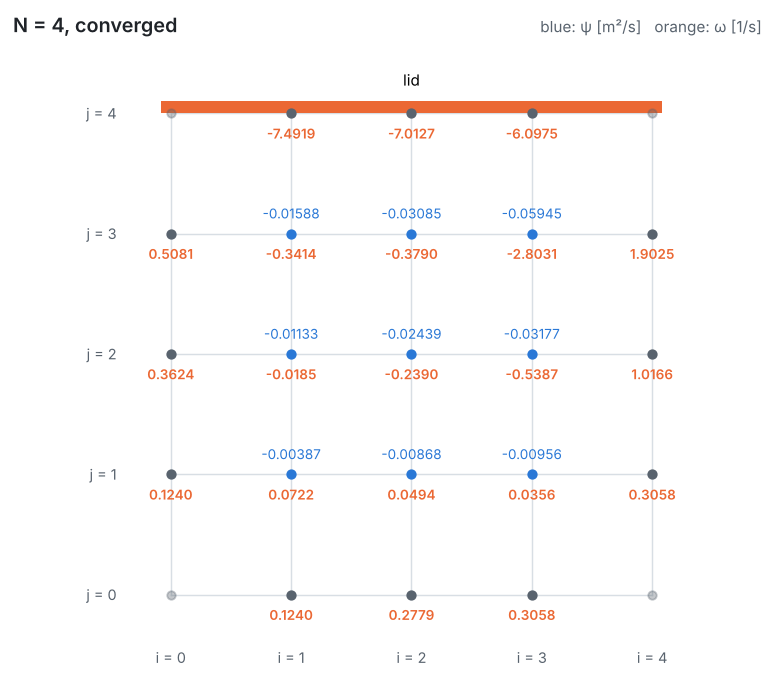

In [16]:
psi_h, w_h, _ = solve_cavity(4, Re)
plots.hand_grid(psi_h, w_h, "N = 4, converged")

---
## Pillar 7 · Post-processing

### The flow pattern

In [17]:
def vortex_centre(psi, N):
    """Node with the smallest psi: the centre of the primary vortex."""
    best = (0.0, 0, 0)
    for j in range(N + 1):
        for i in range(N + 1):
            if psi[j][i] < best[0]:
                best = (psi[j][i], i, j)
    value, i, j = best
    return value, i * L / N, j * L / N


psi_min, xc, yc = vortex_centre(psi, N)
print(f"primary vortex: psi = {psi_min:.5f} m^2/s at (x, y) = ({xc:.4f}, {yc:.4f}) m")
print(f"vorticity at the vortex centre: {w[round(yc * N)][round(xc * N)]:.4f} 1/s")

primary vortex: psi = -0.10038 m^2/s at (x, y) = (0.6250, 0.7500) m
vorticity at the vortex centre: -3.2091 1/s


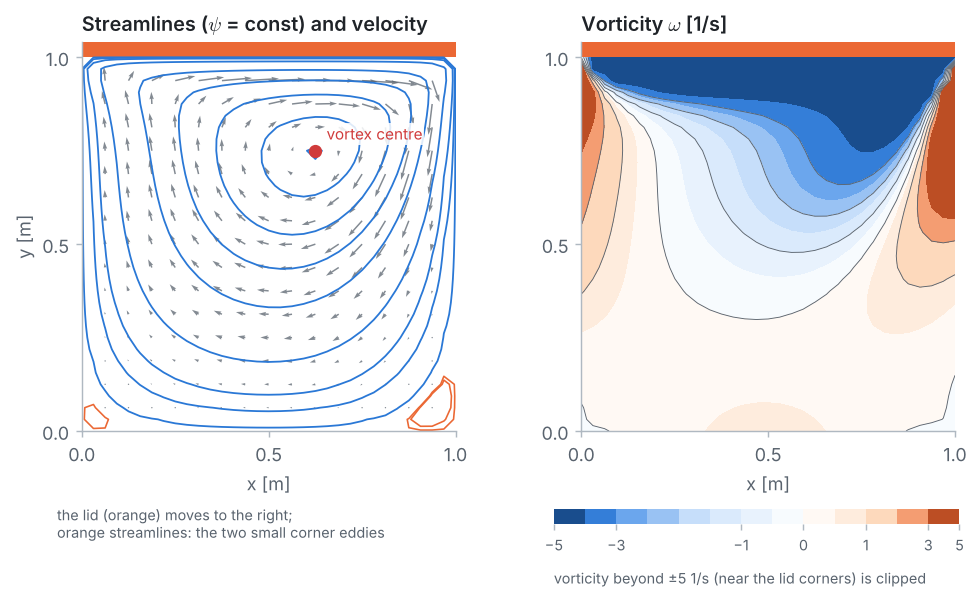

In [18]:
u, v = velocities(psi, N)
plots.flow(x, psi, w, u, v, (xc, yc))

* **Streamlines** (left): one large clockwise vortex fills the cavity. Its centre lies above the middle and to the right of it, pushed downstream by the lid. The fluid circulates around it; the streamlines are packed together just under the lid, where the fluid is fastest.
* **Vorticity** (right): strongly negative (clockwise spin) in a thin layer under the lid, where the velocity falls from $U$ to almost zero over a short distance. The vorticity is created at the walls, mostly at the lid and its two corners, and is carried around by the flow and spread by viscosity. In the core of the vortex it is almost uniform.

### Velocity along the two centre lines, and the benchmark

In [19]:
def centre_lines(psi, N):
    """u along x = 0.5 and v along y = 0.5 (N must be even)."""
    u, v = velocities(psi, N)
    m = N // 2
    u_line = [u[j][m] for j in range(N + 1)]       # vertical centre line, bottom to top
    v_line = [v[m][i] for i in range(N + 1)]       # horizontal centre line, left to right
    return u_line, v_line

### Verification: grid study and comparison with Ghia et al.

There is no exact solution, so we solve the same flow on grids from $N = 4$ to $N = 128$ and watch the results settle. The finest grid has the same 129 × 129 nodes as Ghia et al. **It takes about two minutes in plain Python**; the others are much faster.

In [20]:
grids = [4, 8, 16, 32, 64, 128]
results, psi_mins = {}, []
print("    N       h      iterations   time [s]   psi_min     change    ratio   centre (x, y)")
previous = None
for n_int in grids:
    start = time.time()
    psi_n, w_n, changes_n = solve_cavity(n_int, Re)
    seconds = time.time() - start
    value, xn, yn = vortex_centre(psi_n, n_int)
    results[n_int] = (psi_n, w_n)
    psi_mins.append(value)
    change = f"{value - previous[0]:+.6f}" if previous else "         "
    ratio = f"{previous[1] / (value - previous[0]):5.2f}" if previous and previous[1] else "     "
    print(f"{n_int:5d}   {L / n_int:.5f}   {len(changes_n):8d}   {seconds:8.1f}   {value:.6f}   {change}   {ratio}"
          f"   ({xn:.4f}, {yn:.4f})")
    previous = (value, value - previous[0] if previous else None)
print(f"Ghia et al. (129 x 129 nodes):                   {ghia_psi_min:.6f}                     {ghia_centre}")

    N       h      iterations   time [s]   psi_min     change    ratio   centre (x, y)
    4   0.25000         31        0.0   -0.059454                       (0.7500, 0.7500)
    8   0.12500        136        0.0   -0.067492   -0.008038           (0.6250, 0.7500)
   16   0.06250        241        0.0   -0.090979   -0.023487    0.34   (0.6250, 0.7500)


   32   0.03125        905        0.5   -0.100382   -0.009403    2.50   (0.6250, 0.7500)


   64   0.01562       3297        7.6   -0.102725   -0.002343    4.01   (0.6094, 0.7344)


  128   0.00781      11932      119.8   -0.103324   -0.000599    3.91   (0.6172, 0.7344)
Ghia et al. (129 x 129 nodes):                   -0.103423                     (0.6172, 0.7344)


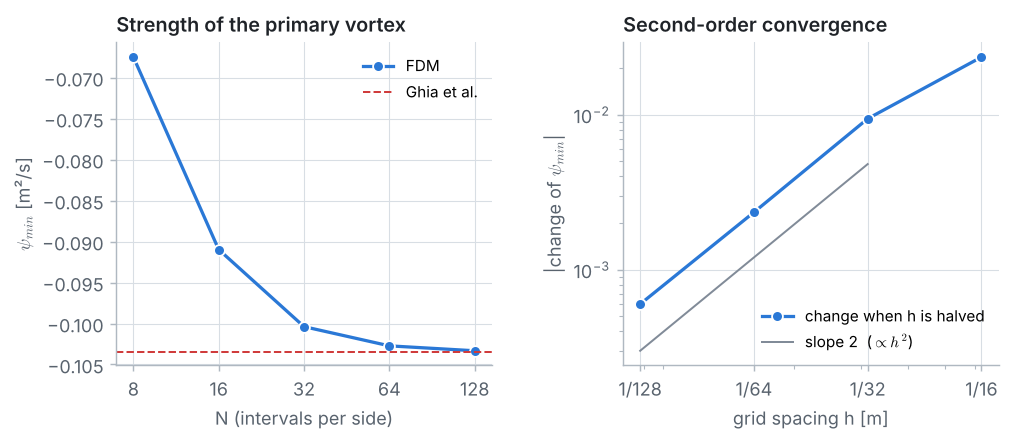

In [21]:
plots.grid_study(grids[1:], psi_mins[1:], ghia_psi_min)

* Each time the grid spacing is halved, the change of $\psi_{min}$ falls by a factor of about 4 (once the grid is fine enough, from $N = 32$ to $64$ and from $64$ to $128$): the scheme is **second-order accurate**, as expected from central differences.
* On 129 × 129 nodes our vortex centre is at exactly the same node as Ghia's, and $\psi_{min}$ agrees with theirs to about 0.1 %.
* The coarsest grids are poor: on $N = 4$ the cell Reynolds number $U h/\nu$ is 25, and the vortex is far too weak ($\psi_{min}$ is less than 60 % of the benchmark).

Now the velocity profiles along the two centre lines, on several grids, against the benchmark points:

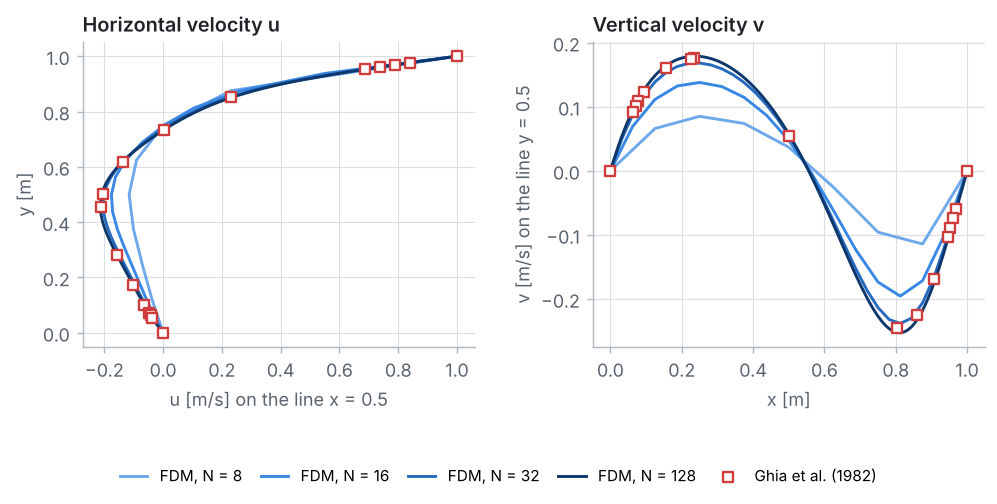

In [22]:
plots.profiles({n: centre_lines(results[n][0], n) for n in (8, 16, 32, 128)},
               ghia_y, ghia_u, ghia_x, ghia_v)

On 129 × 129 nodes the benchmark points fall on our nodes, so we can compare them one by one:

In [23]:
n_fine = 128
u_line, v_line = centre_lines(results[n_fine][0], n_fine)
print("    y      u (FDM)   u (Ghia)  difference  |     x      v (FDM)   v (Ghia)  difference")
worst_u = worst_v = 0.0
for k in range(len(ghia_y)):
    ju = round(ghia_y[k] * n_fine)                     # node closest to Ghia's point
    iv = round(ghia_x[k] * n_fine)
    du = u_line[ju] - ghia_u[k]
    dv = v_line[iv] - ghia_v[k]
    worst_u, worst_v = max(worst_u, abs(du)), max(worst_v, abs(dv))
    print(f"  {ghia_y[k]:.4f}  {u_line[ju]:8.5f}  {ghia_u[k]:8.5f}   {du:+.5f}   |   {ghia_x[k]:.4f}  "
          f"{v_line[iv]:8.5f}  {ghia_v[k]:8.5f}   {dv:+.5f}")
print(f"largest difference: u {worst_u:.5f} m/s, v {worst_v:.5f} m/s")

    y      u (FDM)   u (Ghia)  difference  |     x      v (FDM)   v (Ghia)  difference
  1.0000   1.00000   1.00000   +0.00000   |   1.0000   0.00000   0.00000   +0.00000
  0.9766   0.84313   0.84123   +0.00190   |   0.9688  -0.06208  -0.05906   -0.00302
  0.9688   0.79116   0.78871   +0.00245   |   0.9609  -0.07764  -0.07391   -0.00373
  0.9609   0.74017   0.73722   +0.00295   |   0.9531  -0.09302  -0.08864   -0.00438
  0.9531   0.69057   0.68717   +0.00340   |   0.9453  -0.10814  -0.10313   -0.00501
  0.8516   0.23573   0.23151   +0.00422   |   0.9063  -0.17653  -0.16914   -0.00739
  0.7344   0.00371   0.00332   +0.00039   |   0.8594  -0.23284  -0.22445   -0.00839
  0.6172  -0.13886  -0.13641   -0.00245   |   0.8047  -0.25255  -0.24533   -0.00722
  0.5000  -0.20870  -0.20581   -0.00289   |   0.5000   0.05736   0.05454   +0.00282
  0.4531  -0.21338  -0.21090   -0.00248   |   0.2344   0.17886   0.17527   +0.00359
  0.2813  -0.15701  -0.15662   -0.00039   |   0.2266   0.17865   0.17507 

### Coarse grids and the cell Reynolds number

In Problem 5, central differences wiggled when the cell Péclet number exceeded 2. Here the local cell Reynolds number $|u|\,h/\nu$ is largest just under the lid, where $|u|$ approaches $U$:

In [24]:
print("    N    U h / nu    largest |u| h / nu or |v| h / nu at an interior node")
for n_int in grids:
    u_n, v_n = velocities(results[n_int][0], n_int)
    largest = max(max(abs(u_n[j][i]), abs(v_n[j][i])) for j in range(1, n_int) for i in range(1, n_int))
    print(f"{n_int:5d}   {U * (L / n_int) / nu:7.3f}     {largest * (L / n_int) / nu:7.3f}")

    N    U h / nu    largest |u| h / nu or |v| h / nu at an interior node
    4    25.000       2.495
    8    12.500       3.375
   16     6.250       3.781
   32     3.125       2.523
   64     1.562       1.413
  128     0.781       0.744


The interior nodes always move slower than the lid, so the largest local value is below $U h/\nu$. It is above 2 on the grids up to $N = 32$, yet the iteration converges, and from $N = 32$ on the results converge at second order. The rule $Pe_\Delta \le 2$ of Problem 5 *guarantees* bounded results; breaking it only in a thin layer under the lid does not necessarily spoil the solution. At higher Reynolds numbers the layer under the lid becomes thinner and the cell Reynolds numbers larger, so much finer grids, or the upwind-biased schemes of Problem 5, become necessary.

---
## Summary

* The **stream function** $\psi$ satisfies continuity automatically, and the **vorticity** $\omega$ removes the pressure: the 2D Navier–Stokes equations become a **Poisson equation** $\nabla^2\psi = -\omega$ (Problem 3) and a **convection–diffusion equation** for $\omega$ (Problem 5).
* The no-slip condition gives the wall vorticity through **Thom's formula**, $\omega_{lid} = -2\psi_{N-1}/h^2 - 2U/h$.
* One **Gauss–Seidel** iteration couples the two equations; starting from rest, it converges on every grid from $N = 4$ to $N = 128$.
* The grid study shows **second-order** convergence, and on 129 × 129 nodes the result agrees with the **Ghia et al. benchmark**: same vortex centre, $\psi_{min}$ within about 0.1 %.

## Try it yourself

1. Change `nu` to 0.0025 ($Re = 400$). How do the vortex centre and the velocity profiles change? (Ghia et al. give $\psi_{min} = -0.113909$ at (0.5547, 0.6055) for $Re = 400$. You will need a fine grid and some patience.)
2. Make the lid move to the left (`U = -1.0`). What happens to the vortex and to the sign of $\psi$?
3. Replace the central differences of the vorticity convection by **upwind** differences (Problem 5). Is the vortex centre on $N = 32$ closer to the benchmark or further away?
4. Over-relax the $\psi$ sweep: `psi[j][i] += 1.5 * (new - psi[j][i])`. Count the iterations on $N = 32$ and $N = 64$, then try $N = 4$.
5. *Challenge:* compute the **pressure** from the velocity field. Taking the divergence of the momentum equations gives a Poisson equation for $p$ whose source depends only on derivatives of $u$ and $v$.